# 5. Long history
Does machine learning lose because of too little data? Gold and silver from 2000 (Yahoo), oil from 1986 (FRED spot price). The test period is unchanged (2021–2026).

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

def fred(code):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={code}"
    return pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")[code]

metals = yf.download(["GC=F", "SI=F"], start="2000-01-01")["Close"]
prices = pd.DataFrame({"gold": metals["GC=F"], "silver": metals["SI=F"], "oil": fred("DCOILWTICO")})

[*********************100%***********************]  2 of 2 completed


Download the longer price histories.

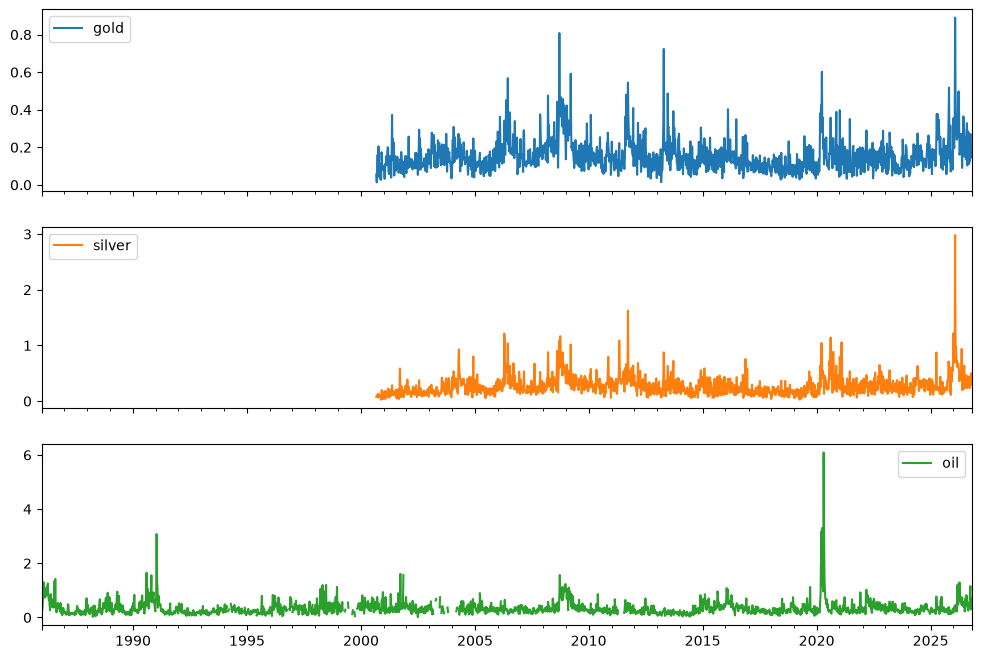

gold      1363
silver    1364
oil       2034
dtype: int64

In [2]:
prices = prices[prices.index.dayofweek < 5]
prices = prices.where(prices > 0)
returns = prices.apply(lambda s: np.log(s.dropna()).diff())

rv = np.sqrt((returns**2).resample("W-FRI").sum(min_count=3)) * np.sqrt(52)
rv.to_csv("rv_long.csv")

rv.plot(subplots=True, figsize=(12, 8))
plt.show()
rv.notna().sum()

Weekly volatility computed for each asset on its own trading days, so the longer oil history isn't cut to the metals' calendar. About 1,360 weeks for the metals and 2,030 for oil.

In [3]:
def har_X(y):
    return pd.DataFrame({"rv": y, "rv4": y.rolling(4).mean(), "rv12": y.rolling(12).mean()})

def forecast(model, y, X, start="2021", train_from=None, refit_every=4):
    data = pd.concat([y.rename("y"), X.shift(1)], axis=1).dropna()
    if train_from:
        data = data.loc[train_from:]
    test_weeks = data.loc[start:].index
    preds = []
    for i in range(0, len(test_weeks), refit_every):
        block = test_weeks[i:i + refit_every]
        train = data.loc[:block[0]].iloc[:-1]
        model.fit(train.drop(columns="y"), train["y"])
        preds.append(pd.Series(model.predict(data.loc[block].drop(columns="y")), index=block))
    return pd.concat(preds)

Walk-forward helper. `train_from='2015'` reproduces the short history of the main study.

In [4]:
har = LinearRegression()
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=0)

fc = {"HAR_short": {}, "HAR_long": {}, "RF_short": {}, "RF_long": {}}
for c in rv:
    X = har_X(rv[c])
    fc["HAR_short"][c] = forecast(har, rv[c], X, train_from="2015")
    fc["HAR_long"][c] = forecast(har, rv[c], X)
    fc["RF_short"][c] = forecast(rf, rv[c], X, train_from="2015")
    fc["RF_long"][c] = forecast(rf, rv[c], X)

fc = {k: pd.DataFrame(v) for k, v in fc.items()}

HAR (linear regression) and Random Forest, each trained on the short and on the full history.

In [5]:
panel = []
for c in rv:
    d = pd.concat([rv[c].rename("y"), har_X(rv[c]).shift(1)], axis=1).dropna()
    d["asset"] = c
    panel.append(d)
panel = pd.concat(panel)
panel.index.name = "week"
X_all = pd.get_dummies(panel.drop(columns="y"), columns=["asset"], dtype=float)

weeks = panel.index.unique().sort_values()
test_weeks = weeks[weeks >= "2021"]
out = []
for i in range(0, len(test_weeks), 4):
    block = test_weeks[i:i + 4]
    tr = panel.index < block[0]
    te = panel.index.isin(block)
    rf.fit(X_all[tr], panel.loc[tr, "y"])
    out.append(pd.DataFrame({"asset": panel.loc[te, "asset"], "pred": rf.predict(X_all[te])}))

fc["RF_pooled"] = pd.concat(out).reset_index().pivot(index="week", columns="asset", values="pred")

**Pooled Random Forest:** one model trained on all three assets together (about 4,800 rows), with asset indicator columns.

In [6]:
test = rv.loc["2021":]
naive = rv.shift(1).loc["2021":]
rmse = lambda f: np.sqrt(((test - f)**2).mean())

table = pd.DataFrame({"naive": rmse(naive)})
for k, v in fc.items():
    table[k] = rmse(v)
table.round(4)

,naive,HAR_short,HAR_long,RF_short,RF_long,RF_pooled
gold,0.1008,0.0833,0.0823,0.0839,0.0839,0.0839
silver,0.2599,0.2016,0.2003,0.2073,0.2007,0.2005
oil,0.2024,0.1699,0.1684,0.1757,0.1766,0.1740


More data lets the forest tie HAR for silver, but not for gold or oil; HAR also improves slightly and stays ahead. Limited data explains only part of the gap. (Oil here is the FRED spot price, so its numbers differ from the main study.)

In [7]:
pd.concat(fc, axis=1).to_csv("long_forecasts.csv")

Save.